# Mini Project 12 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_12.py` (bagian wajib) dan `features/mp12_extension_cnn_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 12 — Melatih Tiny CNN dari Log-Mel
Satu CNN kecil (TinyKWSNet: 2 conv + GAP) dilatih dari log-Mel MP9 (96 frame × 26 Mel).
Normalisasi & augmentasi hanya TRAIN, checkpoint dipilih dari VALIDATION, test tidak dimuat.
Quantization ditunda ke MP15. Status -> `ready_for_mp13`.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json, random, math, copy
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SEED = 2026
EPOCHS = 60
BATCH_SIZE = 8
LR = 1e-3
PATIENCE = 12
TARGET_FRAMES = 96

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

## Helper

In [2]:
def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2), encoding='utf-8')


def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average='macro', zero_division=0))


def load_logmel(sample_id):
    p = ROOT / 'features/logmel/mp09' / f'{sample_id}.npz'
    if not p.exists():
        raise FileNotFoundError(p)
    d = np.load(p, allow_pickle=True)
    x = d['log_mel'].astype(np.float32)
    # Samakan panjang waktu tanpa mengubah jumlah Mel band.
    if x.shape[0] >= TARGET_FRAMES:
        x = x[:TARGET_FRAMES]
    else:
        pad = TARGET_FRAMES - x.shape[0]
        fill = float(np.min(x)) if x.size else 0.0
        x = np.pad(x, ((0, pad), (0, 0)), mode='constant', constant_values=fill)
    label = str(d['label'])
    return x, label

## Langkah 1 — Validasi input serial (gate sebelum training)

In [3]:
status_path = ROOT / 'project_status.json'
if not status_path.exists():
    raise FileNotFoundError('project_status.json tidak ditemukan.')
status = json.loads(status_path.read_text(encoding='utf-8'))
if status.get('status') not in ('ready_for_mp12', 'ready_for_mp13'):
    raise RuntimeError(f"Status harus ready_for_mp12, ditemukan {status.get('status')!r}")

split_path = ROOT / 'splits/mp09_split.json'
split = json.loads(split_path.read_text(encoding='utf-8'))
train_ids = split['train_ids']
val_ids = split['validation_ids']
test_ids = split['test_ids']  # hanya dicatat; tidak dimuat/prediksi pada MP12

clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
assert clf_cfg['test_predictions_generated'] is False, 'MP11 pernah memakai test - jangan lanjut'
classes = list(clf_cfg['classes'])
class_to_idx = {c: i for i, c in enumerate(classes)}
n_logmel = len(list((ROOT/'features/logmel/mp09').glob('*.npz')))
print('status =', status['status'], '| jumlah log-Mel =', n_logmel,
      '| train/val/test =', len(train_ids), len(val_ids), len(test_ids))

status = ready_for_mp12 | jumlah log-Mel = 24 | train/val/test = 16 4 4


## 1) Muat HANYA training dan validation log-Mel; 2) normalisasi global TRAIN-only

In [4]:
train_x, train_y = [], []
for sid in train_ids:
    x, y = load_logmel(sid)
    train_x.append(x); train_y.append(class_to_idx[y])
val_x, val_y = [], []
for sid in val_ids:
    x, y = load_logmel(sid)
    val_x.append(x); val_y.append(class_to_idx[y])
train_x = np.stack(train_x)
val_x = np.stack(val_x)
train_y = np.asarray(train_y, dtype=np.int64)
val_y = np.asarray(val_y, dtype=np.int64)

mu = float(train_x.mean())
sigma = float(train_x.std() + 1e-6)
train_x = (train_x - mu) / sigma
val_x = (val_x - mu) / sigma
print('Input shape:', train_x.shape[1:], '| norm mean/std (TRAIN) =', round(mu, 4), round(sigma, 4))

Input shape: (96, 26) | norm mean/std (TRAIN) = -4.4498 4.0947


## Dataset dengan augmentasi ringan khusus TRAIN (gain, noise, time/frequency masking)

In [5]:
class LogMelDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i].copy()
        if self.augment:
            x *= np.random.uniform(0.95, 1.05)
            x += np.random.normal(0, 0.015, size=x.shape).astype(np.float32)
            if np.random.rand() < 0.5:
                t0 = np.random.randint(0, max(1, x.shape[0]-6))
                x[t0:t0+4, :] = 0
            if np.random.rand() < 0.5:
                f0 = np.random.randint(0, max(1, x.shape[1]-4))
                x[:, f0:f0+3] = 0
        return torch.from_numpy(x[None, ...]).float(), int(self.y[i])


train_loader = DataLoader(LogMelDataset(train_x, train_y, True), batch_size=BATCH_SIZE,
                          shuffle=True, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(LogMelDataset(val_x, val_y, False), batch_size=BATCH_SIZE, shuffle=False)

## Arsitektur TinyKWSNet

In [6]:
class TinyKWSNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(16, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


model = TinyKWSNet(len(classes))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
print(model)

TinyKWSNet(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=16, out_features=4, bias=True)
)


## Training dengan checkpoint berbasis validation macro-F1 + early stopping

In [7]:
best_state = None
best_epoch = 0
best_f1 = -1.0
best_loss = float('inf')
no_improve = 0
history = {'train_loss': [], 'val_loss': [], 'val_accuracy': [], 'val_macro_f1': []}

for epoch in range(1, EPOCHS+1):
    model.train(); total_loss = 0.0; n = 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward(); optimizer.step()
        total_loss += float(loss.item()) * len(yb); n += len(yb)
    train_loss = total_loss / max(n, 1)

    model.eval(); vloss = 0.0; vn = 0; preds = []; refs = []
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = model(xb)
            loss = criterion(logits, yb)
            vloss += float(loss.item()) * len(yb); vn += len(yb)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            refs.extend(yb.cpu().numpy().tolist())
    val_loss = vloss / max(vn, 1)
    val_acc = float(accuracy_score(refs, preds))
    val_f1 = macro_f1(refs, preds)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)
    history['val_macro_f1'].append(val_f1)

    # Checkpoint berdasarkan macro-F1, loss sebagai tie-break.
    improved = (val_f1 > best_f1 + 1e-9) or (abs(val_f1-best_f1) < 1e-9 and val_loss < best_loss)
    if improved:
        best_f1 = val_f1; best_loss = val_loss; best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict()); no_improve = 0
    else:
        no_improve += 1
    if epoch % 10 == 0 or improved:
        print(f'epoch {epoch:02d} train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_F1={val_f1:.3f}' + ('  *' if improved else ''))
    if no_improve >= PATIENCE and epoch >= 20:
        print('Early stopping pada epoch', epoch)
        break

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    Xv = torch.from_numpy(val_x[:, None, :, :]).float()
    val_logits = model(Xv)
    val_pred = val_logits.argmax(1).cpu().numpy()
val_cm = confusion_matrix(val_y, val_pred, labels=np.arange(len(classes)))

epoch 01 train_loss=1.3517 val_loss=1.3713 val_F1=0.125  *
epoch 02 train_loss=1.3184 val_loss=1.3659 val_F1=0.375  *
epoch 03 train_loss=1.3068 val_loss=1.3614 val_F1=0.375  *
epoch 04 train_loss=1.3394 val_loss=1.3545 val_F1=0.375  *
epoch 05 train_loss=1.2963 val_loss=1.3454 val_F1=0.375  *
epoch 06 train_loss=1.2976 val_loss=1.3360 val_F1=0.375  *
epoch 07 train_loss=1.2845 val_loss=1.3252 val_F1=0.375  *
epoch 08 train_loss=1.2717 val_loss=1.3143 val_F1=0.375  *
epoch 09 train_loss=1.2712 val_loss=1.3022 val_F1=0.375  *
epoch 10 train_loss=1.2716 val_loss=1.2897 val_F1=0.375  *
epoch 11 train_loss=1.2660 val_loss=1.2780 val_F1=0.375  *
epoch 12 train_loss=1.2681 val_loss=1.2650 val_F1=0.375  *
epoch 13 train_loss=1.2420 val_loss=1.2521 val_F1=0.375  *
epoch 14 train_loss=1.2841 val_loss=1.2389 val_F1=0.375  *
epoch 15 train_loss=1.2436 val_loss=1.2278 val_F1=0.375  *
epoch 16 train_loss=1.2488 val_loss=1.2174 val_F1=0.375  *
epoch 17 train_loss=1.2616 val_loss=1.2096 val_F1=0.375 

## 3) Resource proxy (test tetap tidak dibaca)

In [8]:
param_count = sum(p.numel() for p in model.parameters())
float32_bytes = int(param_count * 4)
int8_weight_bytes_est = int(param_count)  # estimasi, bukan hasil quantization/deployment.
T, F = train_x.shape[1], train_x.shape[2]
conv1_macs = T * F * 8 * 1 * 3 * 3
T2, F2 = T//2, F//2
conv2_macs = T2 * F2 * 16 * 8 * 3 * 3
fc_macs = 16 * len(classes)
macs = int(conv1_macs + conv2_macs + fc_macs)

## 4) Simpan model dan konfigurasi (tidak ada test prediction)

In [9]:
model_dir = ROOT/'models'; model_dir.mkdir(parents=True, exist_ok=True)
fig_dir = ROOT/'results/figures'; fig_dir.mkdir(parents=True, exist_ok=True)
metric_dir = ROOT/'results/metrics'; metric_dir.mkdir(parents=True, exist_ok=True)
config_dir = ROOT/'config'; config_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir/'mp12_tiny_cnn_state.pt'
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'normalization': {'mean': mu, 'std': sigma}}, model_path)

npz_payload = {}
for name, tensor in model.state_dict().items():
    npz_payload[name.replace('.', '__')] = tensor.detach().cpu().numpy()
npz_payload['classes'] = np.asarray(classes, dtype=object)
npz_payload['normalization_mean'] = np.asarray([mu], dtype=np.float32)
npz_payload['normalization_std'] = np.asarray([sigma], dtype=np.float32)
np.savez_compressed(model_dir/'mp12_tiny_cnn_parameters.npz', **npz_payload)

config = {
    'input_representation': 'log_mel',
    'source_logmel_dir': 'features/logmel/mp09',
    'split_source': 'splits/mp09_split.json',
    'architecture': 'TinyKWSNet_2conv_gap',
    'input_shape_per_sample': [int(T), int(F)],
    'classes': classes,
    'normalization_fit_scope': 'training_only',
    'augmentation_scope': 'training_only',
    'checkpoint_selection_scope': 'validation_only',
    'test_files_loaded': False,
    'test_predictions_generated': False,
    'seed': SEED,
    'batch_size': BATCH_SIZE,
    'learning_rate': LR,
    'max_epochs': EPOCHS,
    'early_stopping_patience': PATIENCE,
    'best_epoch': int(best_epoch),
    'model_file': 'models/mp12_tiny_cnn_state.pt',
    'parameter_file': 'models/mp12_tiny_cnn_parameters.npz',
    'quantization_performed': False,
    'quantization_deferred_to_mp15': True
}
save_json(config_dir/'deep_learning_config.json', config)

report = {
    'n_train': int(len(train_y)),
    'n_validation': int(len(val_y)),
    'n_test_reserved_untouched': int(len(test_ids)),
    'test_ids_loaded_as_features': False,
    'test_predictions_generated': False,
    'input_shape': [int(T), int(F)],
    'parameter_count': int(param_count),
    'float32_parameter_bytes': float32_bytes,
    'estimated_int8_parameter_bytes': int8_weight_bytes_est,
    'estimated_macs_per_inference': macs,
    'best_epoch': int(best_epoch),
    'validation_macro_f1': float(best_f1),
    'validation_accuracy': float(accuracy_score(val_y, val_pred)),
    'validation_confusion_matrix': val_cm.tolist(),
    'history': history,
    'note': 'Angka resource adalah proxy arsitektur. Quantization dan benchmark perangkat dilakukan pada MP15.'
}
save_json(metric_dir/'mp12_deep_learning_metrics.json', report)

## Gambar: learning curve, confusion matrix validation, resource proxy

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 4.5))
e = np.arange(1, len(history['train_loss'])+1)
ax.plot(e, history['train_loss'], label='train loss')
ax.plot(e, history['val_loss'], label='validation loss')
ax.axvline(best_epoch, linestyle='--', label='best checkpoint')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy loss'); ax.set_title('MP12 learning curve')
ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); fig.savefig(fig_dir/'mp12_learning_curve.png', dpi=170); plt.close(fig)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
im = ax.imshow(val_cm, cmap='Blues')
ax.set_xticks(range(len(classes)), classes, rotation=30, ha='right')
ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual'); ax.set_title('MP12 validation confusion matrix')
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, str(val_cm[i, j]), ha='center', va='center')
fig.colorbar(im, ax=ax, fraction=.046, pad=.04); fig.tight_layout(); fig.savefig(fig_dir/'mp12_validation_confusion_matrix.png', dpi=170); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.2, 4.3))
labels = ['Parameters', 'Float32 bytes', 'Est. INT8 bytes', 'MACs / inference']
vals = [param_count, float32_bytes, int8_weight_bytes_est, macs]
ax.bar(labels, vals)
ax.set_yscale('log'); ax.set_ylabel('Count / bytes (log scale)'); ax.set_title('MP12 resource proxy')
for i, v in enumerate(vals): ax.text(i, v*1.08, f'{v:,}', ha='center', fontsize=9)
ax.tick_params(axis='x', rotation=18); fig.tight_layout(); fig.savefig(fig_dir/'mp12_resource_proxy.png', dpi=170); plt.close(fig)

## Langkah 6 — Handoff ke MP13

In [11]:
status['status'] = 'ready_for_mp13'
status['last_completed_mini_project'] = 12
status['mp12'] = {
    'deep_learning_config': 'config/deep_learning_config.json',
    'model_file': 'models/mp12_tiny_cnn_state.pt',
    'parameter_file': 'models/mp12_tiny_cnn_parameters.npz',
    'metrics': 'results/metrics/mp12_deep_learning_metrics.json',
    'test_used': False,
    'quantization_deferred_to_mp15': True
}
save_json(status_path, status)

print('MP12 selesai')
print('best_epoch =', best_epoch)
print('validation_macro_f1 =', round(best_f1, 4))
print('parameters =', param_count)
print('estimated_macs =', macs)
print('test predictions generated = False')
print('status = ready_for_mp13')

MP12 selesai
best_epoch = 41
validation_macro_f1 = 0.375
parameters = 1340
estimated_macs = 898624
test predictions generated = False
status = ready_for_mp13


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp12_extension_cnn_analysis.py`

## FITUR TAMBAHAN MP12 — Diagnosis Underfitting, DS-CNN, Seed Stability, ONNX & Memory Profile
Modul mandiri setelah `mini_project_12.py`. CNN resmi MP12 **tidak diubah**. Test **tidak dimuat**.

Fitur tambahan (materi Bab 12: depthwise-separable CNN, overfitting/early stopping, resource budget):
1. **Diagnosis underfitting** CNN resmi: jumlah langkah optimizer, train-set F1, tren loss.
2. **Varian eksplorasi** dengan protokol identik (norm/augment TRAIN-only, checkpoint VALIDATION):
   a) TinyKWSNet *long-schedule* (arsitektur sama, 300 epoch, OneCycle LR),
   b) **DS-CNN** (depthwise-separable) — biaya ∝ H·W·(K²·M + M·N) vs H·W·K²·M·N,
   c) **TinyKWS-FreqPool**: conv identik, pooling hanya sumbu waktu (jadwal training resmi 60 epoch).
   Model dibekukan + SHA-256 **sebelum** MP13; dievaluasi di MP13 sebagai eksplorasi.
3. **Seed stability** konfigurasi resmi (3 seed) → variasi validation F1.
4. **Export ONNX** + verifikasi onnxruntime vs PyTorch (portabilitas runtime).
5. **Profil memori aktivasi per layer** (peak RAM proxy / tensor arena) TinyKWSNet vs DS-CNN.
6. **Saliency map (gradient × input)** pada validation → wilayah waktu-frekuensi yang dipakai CNN.

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [12]:
from pathlib import Path
import json, copy, hashlib, random, warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import f1_score

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp13',), 'Jalankan mini_project_12.py terlebih dahulu'
dl = json.loads((ROOT/'config/deep_learning_config.json').read_text(encoding='utf-8'))
met = json.loads((ROOT/'results/metrics/mp12_deep_learning_metrics.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
classes = dl['classes']; c2i = {c: i for i, c in enumerate(classes)}
T, F = dl['input_shape_per_sample']
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'; MD = ROOT/'models'
torch.set_num_threads(1)


def load(ids):
    xs, ys = [], []
    for sid in ids:
        d = np.load(ROOT/'features/logmel/mp09'/f'{sid}.npz', allow_pickle=True)
        x = d['log_mel'].astype(np.float32)
        x = x[:T] if x.shape[0] >= T else np.pad(x, ((0, T-x.shape[0]), (0, 0)), constant_values=float(x.min()))
        xs.append(x); ys.append(c2i[str(d['label'])])
    return np.stack(xs), np.asarray(ys)


Xtr, ytr = load(split['train_ids']); Xv, yv = load(split['validation_ids'])   # test TIDAK dimuat
mu, sd = float(Xtr.mean()), float(Xtr.std()+1e-6)
Xtr = (Xtr-mu)/sd; Xv = (Xv-mu)/sd


class TinyKWSNet(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Linear(16, n)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


class DSCNN(nn.Module):
    """Depthwise-separable KWS: conv standar kecil lalu 2 blok depthwise(3x3)+pointwise(1x1)."""
    def __init__(self, n, c=16):
        super().__init__()
        def ds(ci, co):
            return [nn.Conv2d(ci, ci, 3, padding=1, groups=ci, bias=False), nn.BatchNorm2d(ci), nn.ReLU(),
                    nn.Conv2d(ci, co, 1, bias=False), nn.BatchNorm2d(co), nn.ReLU()]
        self.features = nn.Sequential(nn.Conv2d(1, c, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(),
                                      *ds(c, c), *ds(c, c), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Linear(c, n)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


class TinyKWSFreqPool(nn.Module):
    """Conv identik TinyKWSNet, tetapi pooling akhir hanya pada sumbu WAKTU sehingga informasi
    frekuensi (pola formant) tetap sampai ke classifier: 16 kanal x 13 Mel-bin -> Linear."""
    def __init__(self, n):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
                                      nn.AdaptiveAvgPool2d((1, None)))
        self.classifier = nn.Linear(16*(F//2), n)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def make(cls, seed=2026):
    """Seed SEBELUM inisialisasi bobot agar hasil reprodusibel."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    return cls(len(classes))


def augment(xb, rng):
    xb = xb*rng.uniform(0.95, 1.05) + rng.normal(0, 0.015, xb.shape).astype(np.float32)
    for x in xb:
        if rng.random() < 0.5:
            t0 = rng.integers(0, T-6); x[t0:t0+4] = 0
        if rng.random() < 0.5:
            f0 = rng.integers(0, F-4); x[:, f0:f0+3] = 0
    return xb


def train(net, epochs, lr, seed, onecycle=False, patience=None):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    steps_per_epoch = int(np.ceil(len(ytr)/8))
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs*steps_per_epoch) if onecycle else None
    crit = nn.CrossEntropyLoss(); best = (-1, 1e9, None, 0); hist = []; bad = 0
    Xvt = torch.from_numpy(Xv[:, None]).float(); yvt = torch.from_numpy(yv)
    for ep in range(1, epochs+1):
        net.train(); perm = rng.permutation(len(ytr)); tl = 0
        for i in range(0, len(perm), 8):
            b = perm[i:i+8]
            xb = torch.from_numpy(augment(Xtr[b].copy(), rng)[:, None]).float()
            opt.zero_grad(); loss = crit(net(xb), torch.from_numpy(ytr[b])); loss.backward(); opt.step()
            if sch: sch.step()
            tl += float(loss)*len(b)
        net.eval()
        with torch.no_grad():
            lo = net(Xvt); vl = float(crit(lo, yvt)); vf = f1_score(yv, lo.argmax(1).numpy(), average='macro', zero_division=0)
        hist.append((tl/len(ytr), vl, vf))
        if vf > best[0]+1e-9 or (abs(vf-best[0]) < 1e-9 and vl < best[1]):
            best = (vf, vl, copy.deepcopy(net.state_dict()), ep); bad = 0
        else:
            bad += 1
        if patience and bad >= patience and ep >= 20:
            break
    net.load_state_dict(best[2]); net.eval()
    return {'val_f1': float(best[0]), 'val_loss': float(best[1]), 'best_epoch': int(best[3]),
            'epochs_run': len(hist), 'optimizer_steps': len(hist)*steps_per_epoch, 'history': hist}


def train_f1(net):
    with torch.no_grad():
        return float(f1_score(ytr, net(torch.from_numpy(Xtr[:, None]).float()).argmax(1).numpy(), average='macro'))

### 1. Diagnosis underfitting CNN resmi

In [13]:
official = TinyKWSNet(len(classes))
ck = torch.load(ROOT/dl['model_file'], map_location='cpu')
official.load_state_dict(ck['state_dict']); official.eval()
h = met['history']
diag = {'epochs_run': len(h['train_loss']), 'optimizer_steps': len(h['train_loss'])*int(np.ceil(len(ytr)/8)),
        'final_train_loss': h['train_loss'][-1], 'chance_level_loss_ln4': float(np.log(len(classes))),
        'train_set_macro_f1': train_f1(official), 'validation_macro_f1': met['validation_macro_f1'],
        'diagnosis': None}
diag['diagnosis'] = ('UNDERFITTING: train loss masih dekat ln(4) dan train-F1 rendah; '
                     'jumlah langkah optimizer terlalu sedikit (16 sampel / batch 8 = 2 langkah per epoch).'
                     if diag['final_train_loss'] > 0.8*diag['chance_level_loss_ln4'] else 'Konvergen')
print('Diagnosis CNN resmi:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in diag.items()})

Diagnosis CNN resmi: {'epochs_run': 53, 'optimizer_steps': 106, 'final_train_loss': 1.1518, 'chance_level_loss_ln4': 1.3863, 'train_set_macro_f1': 0.5709, 'validation_macro_f1': 0.375, 'diagnosis': 'UNDERFITTING: train loss masih dekat ln(4) dan train-F1 rendah; jumlah langkah optimizer terlalu sedikit (16 sampel / batch 8 = 2 langkah per epoch).'}


### 2. Varian eksplorasi: TinyKWSNet long-schedule & DS-CNN (checkpoint dari VALIDATION)

In [14]:
variants = {}
net_long = make(TinyKWSNet)
variants['tinykws_long'] = {'net': net_long, **train(net_long, 300, 3e-3, seed=2026, onecycle=True)}
net_ds = make(DSCNN)
variants['dscnn'] = {'net': net_ds, **train(net_ds, 300, 3e-3, seed=2026, onecycle=True)}
# jadwal training RESMI (60 epoch, lr 1e-3, patience 12) agar perbandingan arsitektur adil
net_fp = make(TinyKWSFreqPool)
variants['tinykws_freqpool'] = {'net': net_fp, **train(net_fp, 60, 1e-3, seed=2026, patience=12)}


def macs_of(net, shape=(1, 1, T, F)):
    total = 0
    hooks = []
    def hk(m, i, o):
        nonlocal total
        if isinstance(m, nn.Conv2d):
            total += int(o.numel()*m.in_channels//m.groups*m.kernel_size[0]*m.kernel_size[1])
        elif isinstance(m, nn.Linear):
            total += int(m.in_features*m.out_features)
    for m in net.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            hooks.append(m.register_forward_hook(hk))
    with torch.no_grad():
        net(torch.zeros(shape))
    for hh in hooks: hh.remove()
    return total


cand_cfg = {}
for name, v in variants.items():
    net = v['net']
    p = MD/f'mp12_ext_{name}.pt'
    torch.save({'state_dict': net.state_dict(), 'classes': classes, 'normalization': {'mean': mu, 'std': sd},
                'architecture': type(net).__name__}, p)
    v.update({'params': int(sum(q.numel() for q in net.parameters())), 'macs': macs_of(net), 'train_f1': train_f1(net)})
    cand_cfg[name] = {'file': p.relative_to(ROOT).as_posix(), 'sha256': hashlib.sha256(p.read_bytes()).hexdigest(),
                      'architecture': type(net).__name__, 'val_macro_f1': v['val_f1'], 'best_epoch': v['best_epoch'],
                      'params': v['params'], 'macs': v['macs'], 'normalization_fit_scope': 'training_only',
                      'checkpoint_selection_scope': 'validation_only', 'test_files_loaded': False,
                      'role': 'exploratory_candidate_frozen_before_mp13 (bukan kandidat deployment resmi)'}
    print(f"  {name:13s} val F1={v['val_f1']:.3f} (epoch {v['best_epoch']}) train F1={v['train_f1']:.3f} "
          f"params={v['params']} MACs={v['macs']:,}")
official_macs = macs_of(official)
(ROOT/'config/mp12_extension_candidates.json').write_text(json.dumps(cand_cfg, indent=2), encoding='utf-8')

  tinykws_long  val F1=0.667 (epoch 147) train F1=0.365 params=1340 MACs=898,624
  dscnn         val F1=1.000 (epoch 40) train F1=0.604 params=1172 MACs=589,120
  tinykws_freqpool val F1=1.000 (epoch 20) train F1=0.743 params=2108 MACs=899,392


1503

### 3. Seed stability konfigurasi resmi (60 epoch, lr 1e-3, patience 12)

In [15]:
seed_res = []
for s in (2026, 7, 42):
    r = train(make(TinyKWSNet, s), 60, 1e-3, seed=s, patience=12)
    seed_res.append(r['val_f1'])
print('Seed stability (resmi): val F1 =', [round(v, 3) for v in seed_res], '| mean = %.3f ± %.3f' % (np.mean(seed_res), np.std(seed_res)))

Seed stability (resmi): val F1 = [0.375, 0.417, 0.125] | mean = 0.306 ± 0.129


### 4. Export ONNX + verifikasi onnxruntime (model resmi & varian terbaik)

In [16]:
onnx_res = {}
try:
    import onnxruntime as ort
    for name, net in [('official_tinykws', official), ('best_variant', max(variants.values(), key=lambda v: (v['val_f1'], v['train_f1']))['net'])]:
        p = MD/f'mp12_{name}.onnx'
        torch.onnx.export(net, torch.zeros(1, 1, T, F), str(p), input_names=['logmel'], output_names=['logits'],
                          opset_version=17, dynamo=False)
        sess = ort.InferenceSession(str(p), providers=['CPUExecutionProvider'])
        xv = Xv[:, None].astype(np.float32)
        o_ort = np.concatenate([sess.run(None, {'logmel': xv[i:i+1]})[0] for i in range(len(xv))])
        with torch.no_grad():
            o_pt = net(torch.from_numpy(xv)).numpy()
        onnx_res[name] = {'file': p.relative_to(ROOT).as_posix(), 'bytes': p.stat().st_size,
                          'max_abs_logit_diff': float(np.abs(o_ort-o_pt).max()),
                          'argmax_agreement': float(np.mean(o_ort.argmax(1) == o_pt.argmax(1)))}
except Exception as e:  # pragma: no cover
    onnx_res = {'error': repr(e)}
print('ONNX:', onnx_res)

ONNX: {'official_tinykws': {'file': 'models/mp12_official_tinykws.onnx', 'bytes': 6780, 'max_abs_logit_diff': 4.172325134277344e-07, 'argmax_agreement': 1.0}, 'best_variant': {'file': 'models/mp12_best_variant.onnx', 'bytes': 9870, 'max_abs_logit_diff': 3.5762786865234375e-07, 'argmax_agreement': 1.0}}


### 5. Profil memori aktivasi per layer (float32) — tensor arena proxy

In [17]:
def act_profile(net):
    rows = []
    hooks = [m.register_forward_hook(lambda m, i, o, n=n: rows.append((n, type(m).__name__, int(o.numel())*4)))
             for n, m in net.named_modules() if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear))]
    with torch.no_grad():
        net(torch.zeros(1, 1, T, F))
    for hh in hooks: hh.remove()
    inp = T*F*4
    peak = max(inp + rows[0][2], max(rows[i][2]+rows[i+1][2] for i in range(len(rows)-1)))  # in+out ping-pong
    return rows, peak


prof = {}
for name, net in [('official_tinykws', official), ('dscnn', variants['dscnn']['net']), ('tinykws_freqpool', variants['tinykws_freqpool']['net'])]:
    rows, peak = act_profile(net)
    prof[name] = {'layers': [{'layer': n, 'type': t, 'out_bytes': b} for n, t, b in rows], 'peak_pingpong_bytes': int(peak)}
    print(f'  {name:16s} peak activation (ping-pong) = {peak/1024:.1f} KiB')

  official_tinykws peak activation (ping-pong) = 97.5 KiB
  dscnn            peak activation (ping-pong) = 78.0 KiB
  tinykws_freqpool peak activation (ping-pong) = 97.5 KiB


### 6. Saliency (gradient × input) pada validation untuk varian terbaik

In [18]:
best_name = max(variants, key=lambda k: (variants[k]['val_f1'], variants[k]['train_f1']))
bnet = variants[best_name]['net']
xin = torch.from_numpy(Xv[:, None]).float().requires_grad_(True)
out = bnet(xin)
out.gather(1, torch.from_numpy(yv)[:, None]).sum().backward()
sal = (xin.grad*xin).abs().detach().numpy()[:, 0]

ext = {'official_underfitting_diagnosis': diag,
       'exploratory_variants': {k: {kk: vv for kk, vv in v.items() if kk not in ('net', 'history')} for k, v in variants.items()},
       'official_macs_hook_count': official_macs, 'seed_stability_official_val_f1': seed_res,
       'onnx_export': onnx_res, 'activation_memory_profile': prof, 'saliency_model': best_name,
       'candidate_registry': 'config/mp12_extension_candidates.json', 'test_files_loaded': False,
       'note': 'Varian eksplorasi dipilih via validation; CNN resmi MP12 tetap kandidat deployment.'}
(OUT_MET/'mp12_extension_cnn_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
for k, v in variants.items():
    hh = np.array(v['history']); ax[0, 0].plot(hh[:, 0], label=f'{k} train'); ax[0, 0].plot(hh[:, 1], '--', label=f'{k} val')
ax[0, 0].plot(h['train_loss'], 'k', lw=2, label='resmi train'); ax[0, 0].axhline(np.log(4), c='gray', ls=':', label='ln 4 (chance)')
ax[0, 0].set_ylim(0, 2); ax[0, 0].set_title('Loss: resmi (60 ep) vs long-schedule'); ax[0, 0].legend(fontsize=7); ax[0, 0].set_xlabel('epoch')
names = ['resmi'] + list(variants)
ax[0, 1].bar(names, [met['validation_macro_f1']] + [variants[k]['val_f1'] for k in variants], alpha=.8, label='val F1')
ax[0, 1].plot(names, [diag['train_set_macro_f1']] + [variants[k]['train_f1'] for k in variants], 'rs', label='train F1')
ax[0, 1].tick_params(axis='x', rotation=20)
ax[0, 1].scatter(['resmi']*3, seed_res, c='k', zorder=3, label='resmi 3 seed'); ax[0, 1].legend()
ax[0, 1].set_ylim(0, 1.05); ax[0, 1].set_title('Validation macro-F1')
pm = [met['parameter_count']] + [variants[k]['params'] for k in variants]
mc = [official_macs] + [variants[k]['macs'] for k in variants]
nb = len(names)
ax[0, 2].bar(np.arange(nb)-0.2, pm, 0.4, label='params'); ax2 = ax[0, 2].twinx(); ax2.bar(np.arange(nb)+0.2, mc, 0.4, color='C1', label='MACs')
ax[0, 2].set_xticks(range(nb), names, rotation=20); ax[0, 2].set_title('Params (biru) vs MACs (oranye)')
for i in range(3):
    ax[1, i].imshow(sal[i].T, aspect='auto', origin='lower', cmap='hot')
    ax[1, i].set_title(f'Saliency {best_name}: {classes[yv[i]]} (val)'); ax[1, i].set_xlabel('frame'); ax[1, i].set_ylabel('Mel')
for a in ax[0]: a.grid(alpha=.2)
fig.suptitle('MP12 FITUR TAMBAHAN - diagnosis underfitting, DS-CNN, saliency')
fig.tight_layout(); fig.savefig(OUT_FIG/'mp12_extension_cnn_analysis.png', dpi=140); plt.close(fig)
print('Fitur tambahan MP12 selesai -> results/metrics/mp12_extension_cnn_metrics.json')

Fitur tambahan MP12 selesai -> results/metrics/mp12_extension_cnn_metrics.json


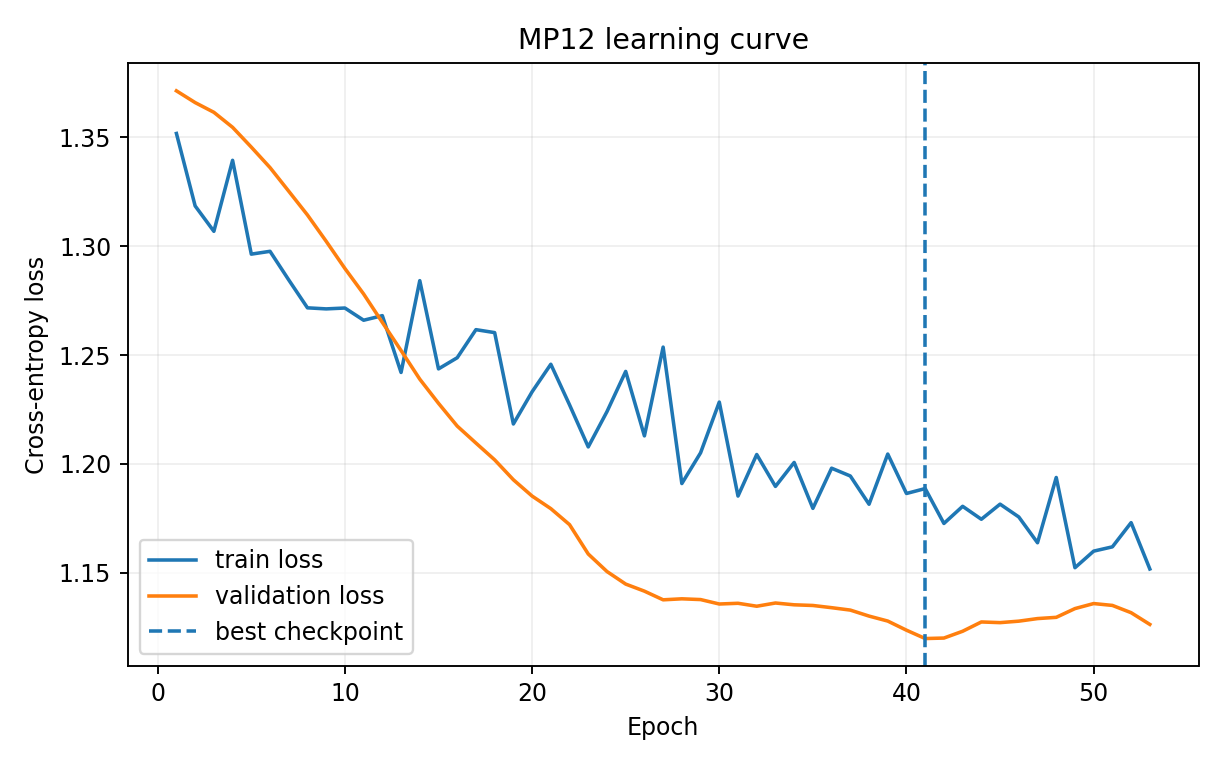

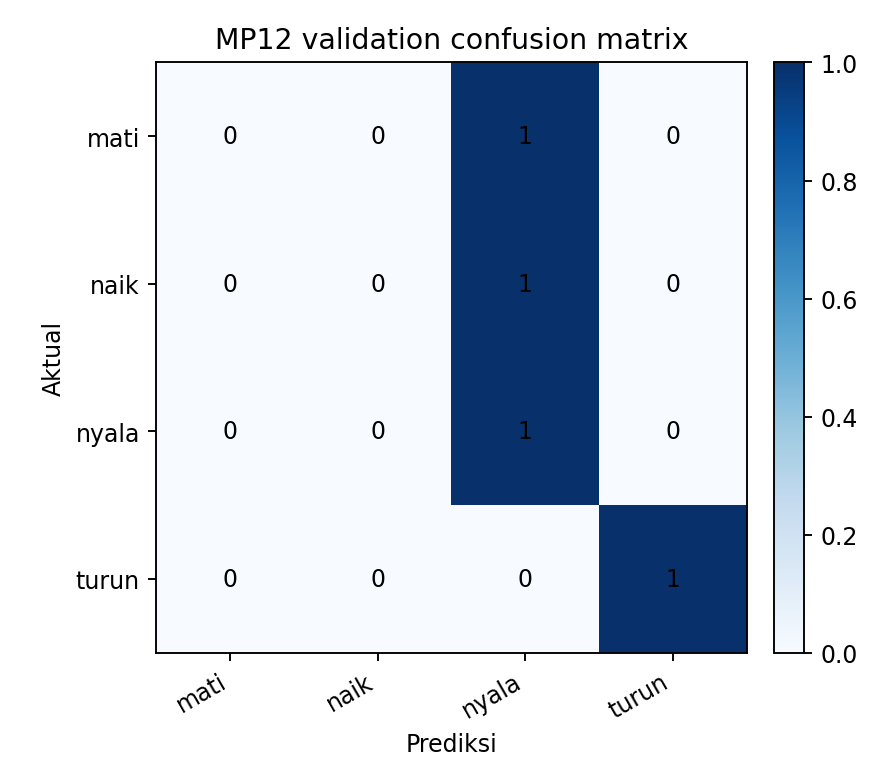

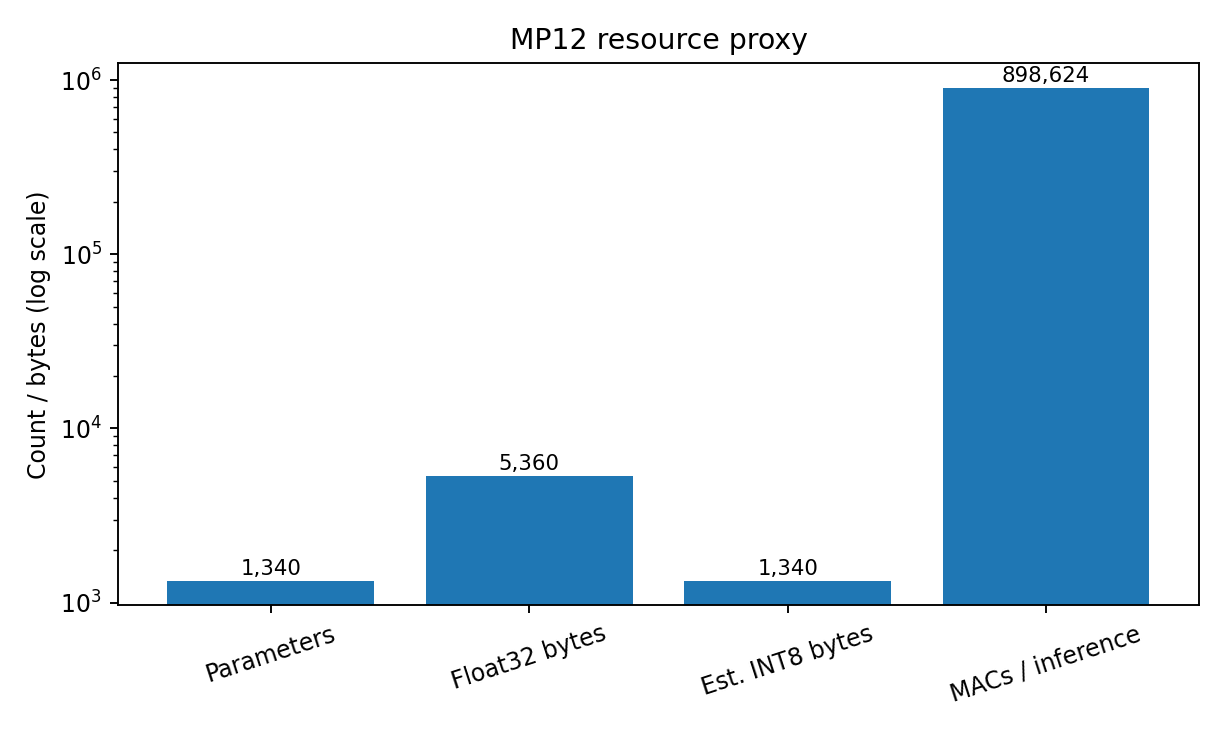

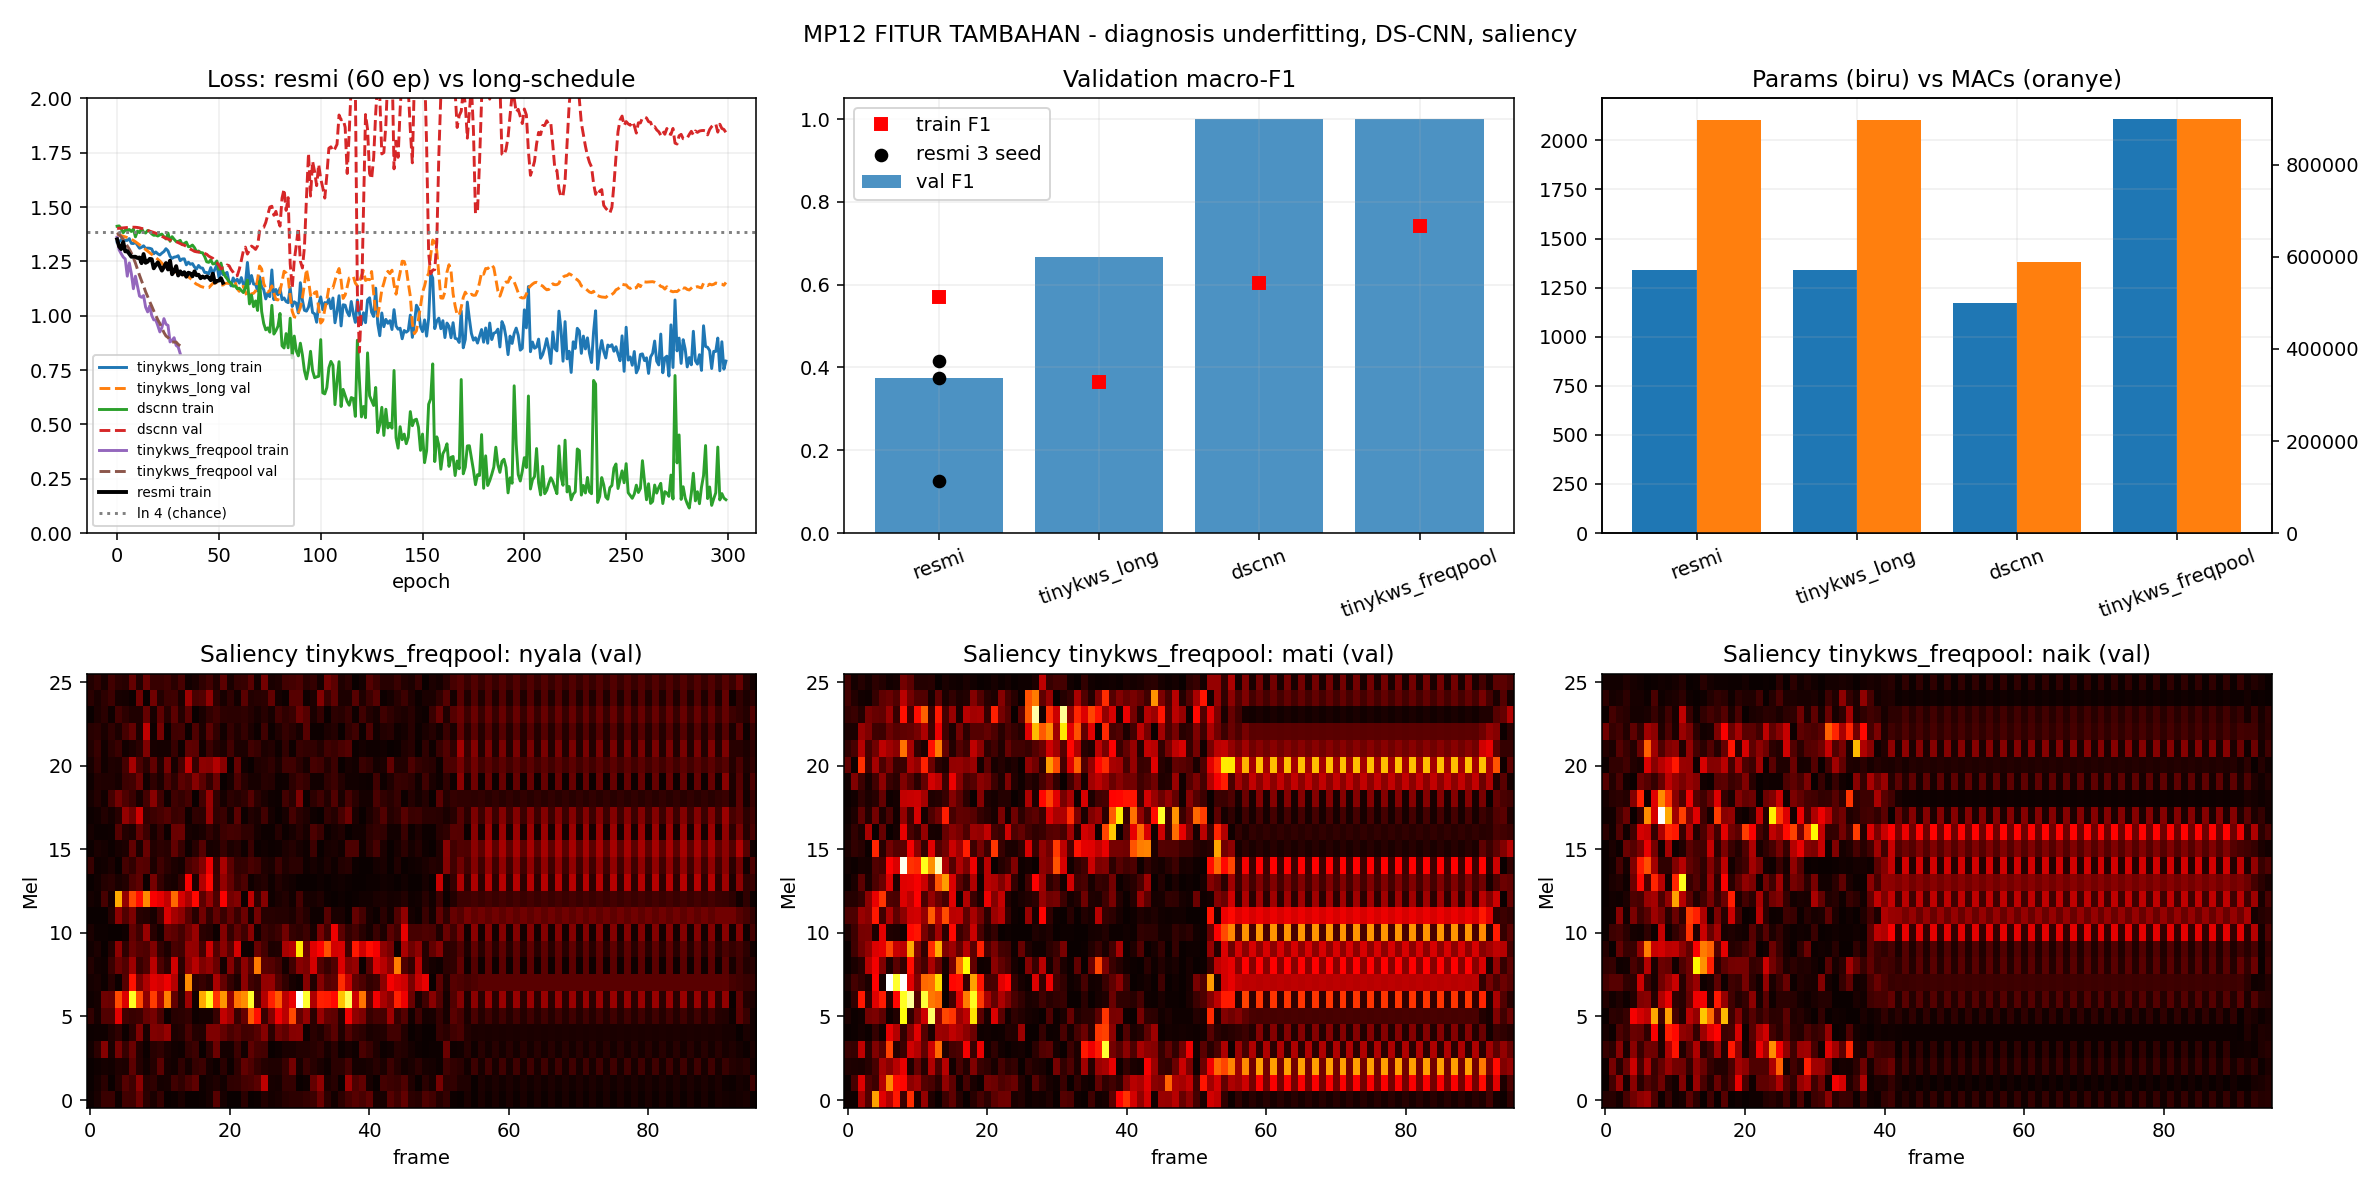

In [19]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp12_learning_curve.png', 'mp12_validation_confusion_matrix.png', 'mp12_resource_proxy.png', 'mp12_extension_cnn_analysis.png']:
        display(Image(filename=str(OUT_FIG/p), width=760))